# Router 분류와 병렬 실행

**이 노트북에서 할 일**

1. 모델 없이, 조건 함수가 내놓은 `Send` 목록으로 고른 분야의 노드만 실행하고 답을 한 칸에 모읍니다.
2. 체크포인트의 단계 번호로 두 분야 노드가 같은 단계에서 실행된 것을 보고, 걸리는 분야가 없을 때를 봅니다.
3. 실제 모델이 분야를 고르는 라우터를 실행하고, 모델 요청 수를 고른 분야 수와 견줍니다.

**준비물** — 2~4절은 모델을 부르지 않아 API 키 없이 실행됩니다.
5~6절은 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 6절에서 그래프를 한 번 실행합니다.
모델 요청은 분류 1번에 고른 분야 수만큼 더해지고, 두 분야를 고르면 3번입니다.
요금표로 어림한 예상 비용은 0.001달러 아래이고, 청구 금액이 아닙니다.

모델이 고르는 분야와 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

읽거나 쓰는 파일은 없고, 체크포인트는 프로그램 메모리에만 둡니다.
앞 챕터에서 배운 함수 하나는 도구 파일 `delegation_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 pydantic 2.13.5, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~3절과 5절을 읽습니다.
분야마다 노드를 두고 `Send`로 함께 보내는 모양과, 모델이 분야를 고르는 자리입니다.
4절은 걸리는 분야가 없는 문의로 바꿔 보는 자리이고, 6절은 모델을 부르는 실행입니다.
이 두 자리는 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch26-delegation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 회색 둥근 상자 START 시작점에서 실선이 파란 상자 classify 분류 노드로 갑니다. 이 상자에는 분야 칸에 이름 목록을 냄, 뒤에 조건 함수 send_to_desks라고 적혀 있습니다. 분류 노드에서 Send라고 적힌 점선 셋이 나란히 놓인 파란 상자 loan_desk 대출 규정 담당, interlibrary_desk 상호대차 담당, facility_desk 시설 담당으로 갑니다. 세 상자에서 실선이 모두 파란 상자 join_answers 종합 노드 분야 이름 차례로 엮음으로 모이고, 거기서 실선이 회색 둥근 상자 END 끝점으로 가는 그림](attachment:03-1-분야마다-함께-보내는-라우터.png)

위에서 아래로 읽습니다.
점선과 실선의 자리는 노트북 2절에서 출력한 구조 문자열의 화살표 여덟 줄과 같습니다.
파란 상자는 우리가 적은 노드이고, 회색 둥근 상자는 시작점과 끝점입니다.
조건 함수 send_to_desks는 노드가 아니어서 따로 상자를 두지 않고 분류 노드 상자 안에 적었습니다.
점선 셋은 갈 수 있는 곳이고, 실제로 가는 곳은 분야 칸에 적힌 이름이 정합니다.
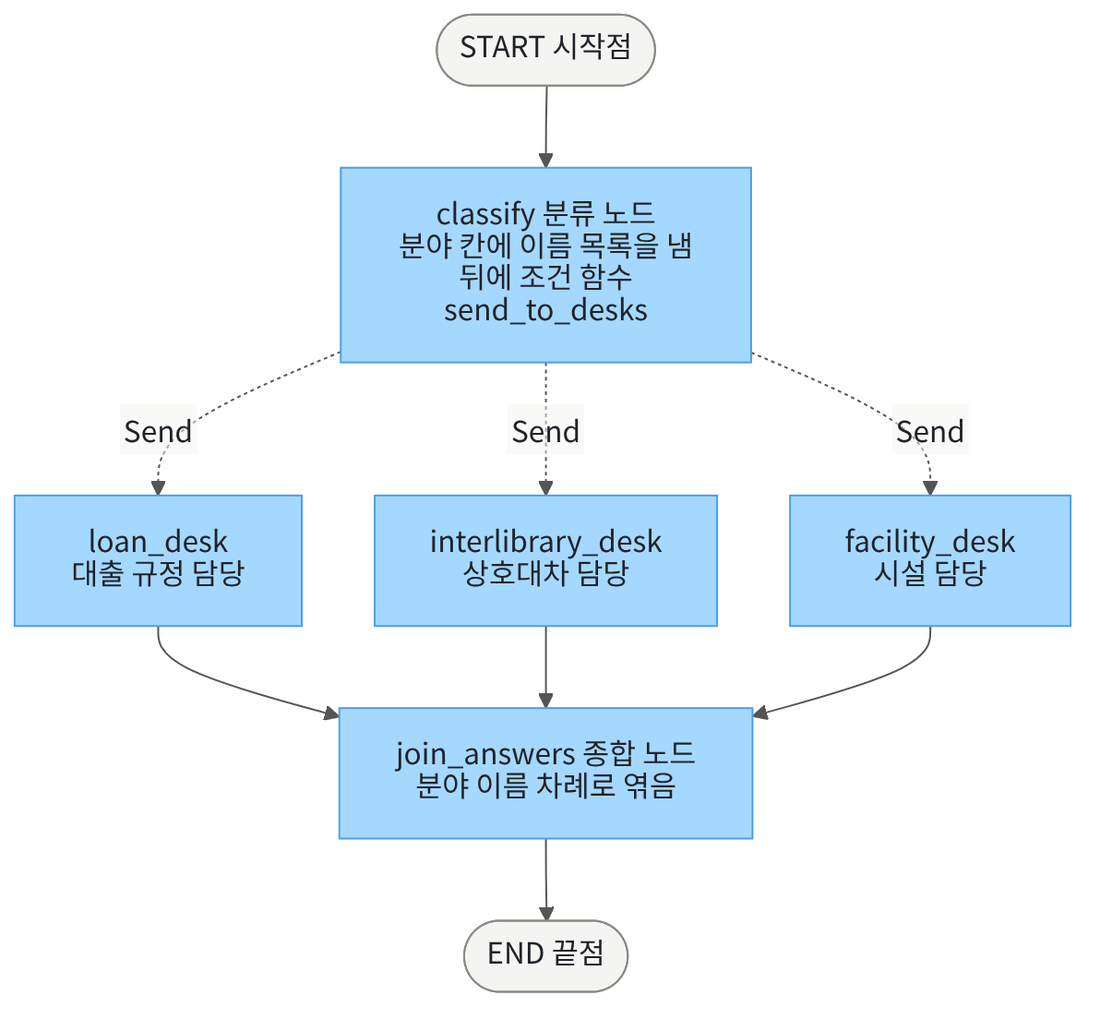

## 1. 준비

이 절에서는 문의를 분류해, 맞는 담당 여럿에게 한꺼번에 보내는 모양을 봅니다.
절 제목의 Router는 라우터를 가리키고, 뜻은 2절에서 풉니다.
제목의 병렬 실행은 Ch 18 03절의 함께 보내기를 가리키고, 본문에서는 그 말로 씁니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("pydantic:", version("pydantic"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
pydantic: 2.13.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `pydantic: 2.13.5`가 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
양식 클래스를 만드는 패키지 pydantic은 langchain과 함께 설치되고, 이 절이 직접 가져와 판을 적었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프를 만드는 이름과 객체 `Send`는 Ch 13에서 썼습니다.
체크포인터 `InMemorySaver`는 Ch 23 01절에서 썼습니다.
양식 클래스를 적는 `BaseModel`·`Field`·`Literal`은 Ch 21 02절에서 썼습니다.

In [2]:
# 상태 형식(Ch 13 01·02절)·그래프와 Send(Ch 13 05절)·체크포인터(Ch 23 01절) 이름을 가져옵니다
import operator
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
# 양식 클래스(Ch 6 03절·Ch 21 02절)·에이전트(Ch 21 01절)·모델(Ch 6 01절)·메시지(Ch 13 04절) 이름을 가져옵니다
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import AnyMessage, HumanMessage
# 앞 챕터에서 배운 함수 하나는 도구 파일에서 가져옵니다
from delegation_tools import sum_usage

print("도구 파일에서 가져온 함수:", "sum_usage")

도구 파일에서 가져온 함수: sum_usage


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: sum_usage`가 보입니다.
Ch 19 05절 함수 `sum_usage`는 목록 안 응답마다 요청 하나로 세고 토큰을 더합니다.

앞에서 배운 함수는 `delegation_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

## 2. 분야마다 노드를 두고 함께 보내기

01절의 서브에이전트는 중앙 에이전트가 담당에게 일을 맡기고 답을 받아 왔습니다.
02절의 핸드오프는 다음 차례에 대화할 담당 자체를 바꾸었습니다.
이 절은 문의를 먼저 분류하고, 고른 담당 여럿에게 이번 차례에 함께 보냅니다.

이렇게 요청을 분류해 맞는 전문 에이전트에게 보내는 쪽을 라우터(router)라고 부릅니다.
고른 담당이 여럿이면 함께 보냅니다.
Ch 18 02절의 라우팅(routing)을 하는 쪽이라는 뜻입니다.

안내 데스크 직원이 문의지를 읽고, 분야별 창구 여러 곳에 한꺼번에 나눠 주는 것과 같습니다.
이 절 코드에서는 분류 노드가 분야 칸에 이름을 적고, 조건 함수가 그 이름마다 `Send`를 만듭니다.
라우터는 이번 차례의 답을 모을 뿐, 다음 차례의 담당을 바꾸지 않습니다.

분야는 01·02절의 두 담당에 시설 담당 `facility_desk`를 더한 셋입니다.
2~4절은 모델을 부르지 않고, 분류도 글자 규칙이 맡습니다.
먼저 분야 이름 셋과, 앞 절반의 분야 노드가 낼 답 한 줄을 정합니다.

In [3]:
# 분야 셋의 이름(노드 이름으로도 씀)과, 앞 절반의 분야 노드가 낼 교재용 답 한 줄을 정합니다
desk_names = ["loan_desk", "interlibrary_desk", "facility_desk"]
desk_notes = {}
desk_notes["loan_desk"] = "대출 규정 담당이 답합니다"
desk_notes["interlibrary_desk"] = "상호대차 담당이 답합니다"
desk_notes["facility_desk"] = "시설 담당이 답합니다"
print("분야 이름:", desk_names)

분야 이름: ['loan_desk', 'interlibrary_desk', 'facility_desk']


**결과 읽기** — 출력 줄 `분야 이름: ['loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
이 이름은 그래프의 노드 이름으로도 씁니다.
답 한 줄은 누가 답했는지만 보여 주려고 정한 교재용 글입니다.

다음 셀은 상태 형식입니다.
분야 칸 `desks`에는 분류가 고른 분야 이름 목록을 적고, 답 칸 `answers`에는 분야마다 낸 답을 모읍니다.
여러 갈래가 같은 단계에 답 칸에 값을 내므로, Ch 13 05절처럼 이어 붙이기 규칙을 적습니다.

In [4]:
# 문의 칸·분야 칸·답 칸·종합 칸을 둔 상태 형식을 만듭니다(답 칸에만 Ch 13 02절 이어 붙이기 규칙)
class RouteState(TypedDict):
    question: str
    desks: list[str]
    answers: Annotated[list[dict], operator.add]
    summary: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
규칙을 적은 칸은 답 칸 하나이고, 문의 칸·분야 칸·종합 칸은 새 값이 오면 덮어씁니다.
종합 칸 `summary`에는 마지막 노드가 답을 한 글로 모아 적습니다.

다음 셀은 분류 노드입니다.
문의 글에 「연장」이 있으면 대출 규정 담당, 「다른 도서관」이 있으면 상호대차 담당을 고릅니다.
「운영」이 있으면 시설 담당을 고르고, 걸리는 말이 여럿이면 모두 고릅니다.

In [5]:
# 앞 절반의 분류 노드입니다. 문의 글에 든 말로 분야를 고르고, 고른 이름 목록을 분야 칸에 냅니다
def classify_by_words(state):
    desks = []
    if "연장" in state["question"]:
        desks.append("loan_desk")
    if "다른 도서관" in state["question"]:
        desks.append("interlibrary_desk")
    if "운영" in state["question"]:
        desks.append("facility_desk")
    return {"desks": desks}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
세 `if`가 따로 검사하므로, 고른 분야는 하나도 없을 수도, 셋일 수도 있습니다.
분류는 이 셀의 글자 규칙이 정하고, 5절에서는 모델이 정합니다.

다음 셀은 분류 노드 뒤에 둘 조건 함수입니다.
Ch 13 05절처럼 분야 칸의 이름마다 `Send` 하나를 만들어 목록으로 내놓습니다.
객체 `Send`의 둘째 자리 딕셔너리는 그 실행 하나만 읽는 갈래별 상태가 됩니다.

In [6]:
# 분류 노드 뒤에 둘 조건 함수입니다. 분야 칸의 이름마다 Send 하나를 만들어 목록으로 내놓습니다
def send_to_desks(state):
    sends = []
    for desk in state["desks"]:
        # Send의 첫 자리는 갈 노드 이름, 둘째 자리는 그 실행에만 넘길 갈래별 상태입니다(Ch 13 05절)
        branch = {"desk": desk, "question": state["question"]}
        sends.append(Send(desk, branch))
    return sends

**결과 읽기** — 정의 셀이라 출력이 없습니다.
갈래별 상태에는 분야 이름과 문의 글 둘을 담았습니다.
분야 이름을 함께 보내야, 노드가 낸 답에도 어느 분야의 답인지 적을 수 있습니다.

다음 셀은 앞 절반의 분야 노드입니다.
세 분야 노드가 이 함수 하나를 함께 쓰고, 갈래별 상태의 분야 이름으로 누구인지 가립니다.
답 칸에는 분야 이름과 답 한 줄을 한 딕셔너리로 함께 냅니다.

In [7]:
# 앞 절반의 분야 노드입니다. 갈래별 상태의 분야 이름을 읽어, 이름과 답 한 줄을 함께 답 칸에 냅니다
def desk_reply(state):
    answer = {"desk": state["desk"], "reply": desk_notes[state["desk"]]}
    return {"answers": [answer]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
Ch 13 05절에서 본 대로, 결과가 모이는 차례는 우리가 정하지 않습니다.
그래서 답마다 분야 이름을 함께 담아, 모인 차례와 관계없이 누구의 답인지 알게 합니다.

다음 셀은 답을 모으는 종합 노드입니다.
분야 이름 목록의 차례대로 답 칸에서 그 분야의 답을 찾아, 한 줄씩 이어 붙입니다.
모델을 부르지 않는 보통 함수입니다.

In [8]:
# 종합 노드입니다. 분야 이름 목록의 차례대로 답 칸에서 그 분야의 답을 찾아 한 줄씩 이어 붙입니다
def join_answers(state):
    summary = ""
    for desk in desk_names:
        for answer in state["answers"]:
            if answer["desk"] == desk:
                summary = summary + "[" + desk + "] " + answer["reply"] + "\n"
    return {"summary": summary}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
종합 칸의 줄 차례는 답 칸에 모인 차례가 아니라, 이 함수가 도는 분야 이름 차례를 따릅니다.
Ch 13 05절이 자리 번호로 차례를 맞춘 것과 같은 생각입니다.

다음 셀은 노드 다섯과 엣지로 그래프를 만들고, 체크포인터를 붙여 컴파일합니다.
세 분야 노드는 `for` 한 번으로 등록하고, 저마다 종합 노드로 가는 고정 엣지를 둡니다.
조건부 엣지의 셋째 자리에는 조건 함수가 갈 수 있는 분야 이름 목록을 적습니다.

In [9]:
# 노드 다섯과 엣지로 그래프를 만들고, 체크포인터를 붙여 컴파일합니다(출력 없음)
router_builder = StateGraph(RouteState)
router_builder.add_node("classify", classify_by_words)
router_builder.add_node("join_answers", join_answers)
# 세 분야 노드는 함수 하나를 함께 쓰고, 저마다 종합 노드로 가는 고정 엣지를 둡니다
for desk in desk_names:
    router_builder.add_node(desk, desk_reply)
    router_builder.add_edge(desk, "join_answers")
router_builder.add_edge(START, "classify")
# 셋째 자리의 이름 목록은 조건 함수가 갈 수 있는 곳이라, 구조 문자열에 점선으로 그려집니다
router_builder.add_conditional_edges("classify", send_to_desks, desk_names)
router_builder.add_edge("join_answers", END)
router_graph = router_builder.compile(checkpointer=InMemorySaver())

**결과 읽기** — 설계 객체를 만들고 컴파일만 하는 셀이라 출력이 없습니다.
분야 노드 셋이 모두 종합 노드로 가는 엣지를 가졌습니다.
종합 노드가 몇 번 실행되는지는 3절에서 체크포인트로 봅니다.

다음 셀은 등록한 노드와 구조 문자열의 화살표 줄을 출력합니다.

In [10]:
# 등록한 노드와, 그래프가 스스로 그린 구조 문자열에서 화살표가 있는 줄을 출력합니다(02절과 같은 모양)
print("등록한 노드:", list(router_builder.nodes))
structure_text = router_graph.get_graph().draw_mermaid()
print("구조 문자열에서 화살표가 있는 줄:")
for line in structure_text.split("\n"):
    if "->" in line:
        print(line.strip())

등록한 노드: ['classify', 'join_answers', 'loan_desk', 'interlibrary_desk', 'facility_desk']
구조 문자열에서 화살표가 있는 줄:
__start__ --> classify;
classify -.-> facility_desk;
classify -.-> interlibrary_desk;
classify -.-> loan_desk;
facility_desk --> join_answers;
interlibrary_desk --> join_answers;
loan_desk --> join_answers;
join_answers --> __end__;


**결과 읽기** — 출력 줄 `등록한 노드: ['classify', 'join_answers', 'loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
라벨 줄 아래 `classify -.-> loan_desk;`처럼 분류 노드에서 세 분야로 가는 줄은 점선입니다.
조건 함수가 고를 수 있는 곳이라 점선이고, `loan_desk --> join_answers;` 같은 고정 엣지는 실선입니다.
조건 함수 `send_to_desks`는 노드가 아니라 등록한 노드 목록에 없습니다.

## 3. 두 분야가 걸린 문의

첫 문의는 책 연장과 토요일 운영 시간을 함께 묻습니다.
실행 전에 예상해 봅니다.
글자 규칙이 대출 규정 담당과 시설 담당을 고르고, 두 분야 노드만 실행될 것입니다.

다음 셀은 스레드 `route-1`에 첫 문의를 넣어 실행합니다.

In [11]:
# 스레드 route-1에 두 분야가 걸리는 문의를 넣어 실행하고, 분야 칸·답 칸·종합 칸을 봅니다
first_question = "빌린 책을 연장하려면 어떻게 하나요? 토요일 운영 시간도 알려 주세요."
route_config = {"configurable": {"thread_id": "route-1"}}
first_input = {"question": first_question, "desks": [], "answers": [], "summary": ""}
first_result = router_graph.invoke(first_input, route_config)
print("분야 칸:", first_result["desks"])
print("답 칸 줄 수:", len(first_result["answers"]))
print("종합 칸:")
print(first_result["summary"])

분야 칸: ['loan_desk', 'facility_desk']
답 칸 줄 수: 2
종합 칸:
[loan_desk] 대출 규정 담당이 답합니다
[facility_desk] 시설 담당이 답합니다



**결과 읽기** — 출력 줄 `분야 칸: ['loan_desk', 'facility_desk']`와 `답 칸 줄 수: 2`가 보입니다.
고른 분야 수만큼 답이 모였습니다.
라벨 줄 아래 종합 칸은 `[loan_desk] 대출 규정 담당이 답합니다`와 `[facility_desk] 시설 담당이 답합니다` 두 줄입니다.
상호대차 담당의 줄이 없어, 고르지 않은 분야 노드는 실행되지 않았습니다.

다음 셀은 이 실행이 저장한 체크포인트를 Ch 23 01절 메서드 `get_state_history`로 읽습니다.
체크포인트마다 단계 번호와, 그다음 단계에서 실행할 노드를 출력합니다.
이 메서드는 최신 체크포인트부터 내놓으므로, 아래 줄부터 거꾸로 읽습니다.

In [12]:
# 저장된 체크포인트마다 단계 번호와 다음에 실행할 노드를 봅니다(Ch 23 01절 — 최신 체크포인트부터 나옴)
print("단계 번호 | 다음에 실행할 노드")
for snapshot in router_graph.get_state_history(route_config):
    # 칸 metadata의 step이 단계 번호이고, next는 그다음 단계에서 실행할 노드 이름입니다
    print(snapshot.metadata["step"], "|", snapshot.next)

단계 번호 | 다음에 실행할 노드
3 | ()
2 | ('join_answers',)
1 | ('loan_desk', 'facility_desk')
0 | ('classify',)
-1 | ('__start__',)


**결과 읽기** — 라벨 줄 아래 맨 아래 줄은 `-1 | ('__start__',)`이고, 위로 가며 단계가 늘어납니다.
줄 `1 | ('loan_desk', 'facility_desk')`는 단계 1이 끝난 뒤 다음에 실행할 노드가 둘이라는 뜻입니다.
두 분야 노드는 같은 단계 2에서 함께 실행되었습니다.
줄 `2 | ('join_answers',)`로 종합 노드는 단계 3에서 한 번 실행되었고, 맨 위 줄 `3 | ()`에서 끝났습니다.

같은 단계에서 실행되었다는 것은 차례에 관한 사실입니다.
두 노드를 함께 실행해 걸린 시간이 얼마나 줄었는지는 이번에 재지 않았습니다.

## 4. 걸리는 분야가 없으면

이번에는 값 하나만 바꿔 봅니다.
바꿀 값은 문의 글이고, 글자 규칙에 걸리는 말이 없는 글을 새 스레드 `route-2`에 넣습니다.
실행 전에 예상해 봅니다.
분야 칸이 빈 목록이면 `Send`도 없으니, 분야 노드와 종합 노드가 하나도 실행되지 않을 것입니다.

In [13]:
# 값 바꿔 보기: 글자 규칙에 걸리는 말이 없는 문의를 새 스레드 route-2에 넣어 실행합니다
empty_config = {"configurable": {"thread_id": "route-2"}}
empty_input = {"question": "자료실에 우산을 두고 온 것 같아요.", "desks": [], "answers": [], "summary": ""}
empty_result = router_graph.invoke(empty_input, empty_config)
print("분야 칸:", empty_result["desks"])
print("답 칸 줄 수:", len(empty_result["answers"]))
print("종합 칸이 빈 글인가:", empty_result["summary"] == "")
empty_state = router_graph.get_state(empty_config)
print("마지막 체크포인트의 단계 번호:", empty_state.metadata["step"], "| 다음에 실행할 노드:", empty_state.next)

분야 칸: []
답 칸 줄 수: 0
종합 칸이 빈 글인가: True
마지막 체크포인트의 단계 번호: 1 | 다음에 실행할 노드: ()


**결과 읽기** — 오류 없이 셀이 끝났고, 출력 줄 `분야 칸: []`과 `답 칸 줄 수: 0`이 보입니다.
출력 줄 `종합 칸이 빈 글인가: True`로, 종합 노드도 실행되지 않았습니다.
출력 줄 `마지막 체크포인트의 단계 번호: 1 | 다음에 실행할 노드: ()`는 단계 1 뒤에 남은 노드가 없다는 뜻입니다.
분류 노드만 실행되고, 그래프가 조용히 끝났습니다.

02절 4절에서는 `goto`에 없는 노드 이름을 적자 조용히 끝났습니다.
이 장면은 조용히 끝나는 두 번째 경우이고, 이번에는 경고 글도 없었습니다.
걸리는 분야가 없을 때의 답은 코드가 따로 정해야 하고, 지나간 노드를 출력해 보는 편이 안전합니다.

## 5. 모델이 분야를 고르는 라우터

이제 분류를 실제 모델에 맡기고, 분야 노드는 전문 에이전트를 부르게 바꿉니다.
그래프 모양은 2절과 같고, 분류 노드와 분야 노드의 속만 바뀝니다.
공식 문서의 라우터도 분류에 모델을 쓰고, 고른 분야마다 `Send`로 보냅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [14]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [15]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
분류 모델과 전문 에이전트 셋이 이 모델 객체 하나를 함께 씁니다.

다음 셀은 세 담당의 규정 글을 정합니다.
대출 규정은 01절 글, 상호대차 규정은 02절 글 그대로입니다.
시설 규정은 이 절이 정한 교재용 한 문장이고, 운영 시각은 Ch 21 01절 규정 글과 같습니다.

In [16]:
# 세 담당의 교재용 규정 글을 정합니다(대출은 01절, 상호대차는 02절 글 그대로이고, 시설은 이 절이 정한 한 문장)
loan_rules = "[교재용 대출·반납 규정] 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다. 반납 예정일 전에 한 번, 7일 연장할 수 있습니다."
loan_rules = loan_rules + " 예약한 사람이 있는 책은 연장할 수 없습니다. 연체한 일수만큼 새 대출이 제한됩니다."
interlibrary_rules = "[교재용 상호대차 규정] 다른 도서관의 책은 자료실 창구에서 상호대차로 신청합니다."
interlibrary_rules = interlibrary_rules + " 신청한 책은 보통 3~5일 뒤에 도착합니다."
interlibrary_rules = interlibrary_rules + " 책이 도착하면 문자로 알리고, 7일 안에 찾아가야 합니다."
facility_rules = "[교재용 시설 규정] 자료실은 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다."
print("시설 규정:", facility_rules)

시설 규정: [교재용 시설 규정] 자료실은 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.


**결과 읽기** — 출력 줄 `시설 규정: [교재용 시설 규정] 자료실은 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.`가 보입니다.
세 규정 글 모두 교재용으로 만든 글이고, 실제 도서관 규정이 아닙니다.

다음 셀은 이 규정 글로 도구 없는 전문 에이전트 셋을 만듭니다.
시스템 메시지 글에는 문의 가운데 자기 규정에 해당하는 부분에만 한 문장으로 답하라고 적습니다.
분야 노드가 분야 이름으로 에이전트를 찾도록, 딕셔너리에 분야 이름을 키로 담습니다.

In [17]:
# 세 규정 글로 도구 없는 전문 에이전트 셋을 만들고, 분야 이름으로 찾을 수 있게 딕셔너리에 담습니다
answer_rule = " 문의 가운데 아래 교재용 규정에 해당하는 부분에만 한 문장의 한국어로 답하세요.\n"
loan_text = "도서관 자료실의 대출 규정 담당입니다." + answer_rule + loan_rules
interlibrary_text = "도서관 자료실의 상호대차 담당입니다." + answer_rule + interlibrary_rules
facility_text = "도서관 자료실의 시설 담당입니다." + answer_rule + facility_rules
desk_agents = {}
desk_agents["loan_desk"] = create_agent(model, tools=[], system_prompt=loan_text, name="loan_desk")
desk_agents["interlibrary_desk"] = create_agent(model, tools=[], system_prompt=interlibrary_text, name="interlibrary_desk")
desk_agents["facility_desk"] = create_agent(model, tools=[], system_prompt=facility_text, name="facility_desk")
print("전문 에이전트:", list(desk_agents))

전문 에이전트: ['loan_desk', 'interlibrary_desk', 'facility_desk']


**결과 읽기** — 출력 줄 `전문 에이전트: ['loan_desk', 'interlibrary_desk', 'facility_desk']`가 보입니다.
딕셔너리의 키는 2절 분야 이름과 같고, 에이전트 이름도 같은 글로 붙였습니다.
01절에서 본 것처럼 도구 없는 전문 에이전트는 한 번 부르면 모델 요청이 1번입니다.

다음 셀은 분류 모델이 채울 양식 클래스입니다.
클래스 `BaseModel`을 이어받은 클래스는 칸 이름과 칸에 들어갈 값의 형식을 적는 틀입니다.
주문서 양식에 칸마다 적을 것을 정해 두는 것과 같고, 뜻은 Ch 2 10절에 있습니다.
이 셀에서는 칸 `desks` 하나에, 분야 이름 셋 가운데에서 고른 이름의 목록만 받게 적습니다.
표시 `Literal`은 Ch 21 02절처럼 괄호 안 값 가운데 하나만 받고, `list[…]`로 감싸 그런 값의 목록을 받습니다.

In [18]:
# 분류 모델이 채울 양식 클래스입니다. 칸 desks에는 분야 이름 셋 가운데에서 고른 이름의 목록이 들어갑니다
class DeskChoice(BaseModel):
    desks: list[Literal["loan_desk", "interlibrary_desk", "facility_desk"]] = Field(description="문의에 답할 담당 이름 목록")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
빈 목록도 이 형식에 맞으므로, 모델은 분야를 하나도 고르지 않을 수 있습니다.
함수 `Field`의 설명 글은 Ch 6 03절에서 본 대로 칸의 뜻을 알려 줄 뿐, 규칙이 아닙니다.

다음 셀은 분류에 쓸 시스템 메시지 글을 정하고, 모델 객체에 양식 클래스를 붙입니다.
Ch 6 03절처럼 인자 `include_raw=True`를 주면 결과가 딕셔너리가 됩니다.
키 `raw`에는 모델 응답, `parsed`에는 양식 클래스 객체, `parsing_error`에는 읽기 오류가 담깁니다.
이 절은 모델 응답도 받아, 분류 요청까지 셉니다.

In [19]:
# 분류에 쓸 시스템 메시지 글을 정하고, 모델 객체에 양식 클래스를 붙여 분류 모델을 만듭니다(요청은 아직 없음)
classify_text = "도서관 자료실 문의 창구의 안내 도우미입니다. 문의를 읽고 답할 담당을 모두 고르세요."
classify_text = classify_text + " loan_desk는 대출·반납·연장·연체, interlibrary_desk는 다른 도서관 책을 빌려 오는 상호대차를 맡습니다."
classify_text = classify_text + " facility_desk는 자료실 운영 시간과 시설을 맡습니다. 맡을 담당이 없으면 빈 목록을 내세요."
# include_raw=True를 주면 결과가 딕셔너리가 되고, 키 raw에 모델 응답이 함께 담깁니다(Ch 6 03절)
classifier = model.with_structured_output(DeskChoice, include_raw=True)
print("분류 모델의 종류:", type(classifier).__name__)

분류 모델의 종류: RunnableSequence


**결과 읽기** — 출력 줄 `분류 모델의 종류: RunnableSequence`가 보입니다.
Ch 6 03절처럼 이 셀은 호출 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
시스템 메시지 글에는 세 분야가 맡는 일과, 맡을 담당이 없으면 빈 목록을 내라는 문장을 적었습니다.

다음 셀은 뒤 절반의 상태 형식입니다.
2절 상태 형식에 응답 칸 `responses`를 더해, 분류 모델과 전문 에이전트의 응답을 모읍니다.
칸 구성이 달라 이름을 새로 붙이고, 응답 칸에도 이어 붙이기 규칙을 적습니다.

In [20]:
# 2절 상태 형식에 응답 칸을 더한 상태 형식을 만듭니다(응답 칸에도 이어 붙이기 규칙, 칸 구성이 달라 새 이름)
class ModelRouteState(TypedDict):
    question: str
    desks: list[str]
    answers: Annotated[list[dict], operator.add]
    summary: str
    responses: Annotated[list[AnyMessage], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
응답 칸의 응답 하나가 모델 요청 하나이므로, 6절에서 함수 `sum_usage`로 셉니다.
응답의 형식은 Ch 13 04절의 공통 형식 `AnyMessage`로 적었습니다.

다음 셀은 모델이 분야를 고르는 분류 노드입니다.
문의 글을 시스템 메시지 글과 함께 분류 모델에 보냅니다.
고른 분야 목록은 분야 칸에, 결과의 모델 응답은 응답 칸에 냅니다.

In [21]:
# 뒤 절반의 분류 노드입니다. 분류 모델이 고른 이름 목록은 분야 칸에, 모델 응답은 응답 칸에 냅니다
def classify_by_model(state):
    messages = [("system", classify_text), ("user", state["question"])]
    result = classifier.invoke(messages)
    choice = result["parsed"]
    return {"desks": choice.desks, "responses": [result["raw"]]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
분야 칸의 값은 2절 글자 규칙과 같은 모양의 이름 목록이라, 조건 함수 `send_to_desks`를 그대로 씁니다.
읽기 오류가 나면 키 `parsed`가 `None`이 되어 이 노드가 멈추고, 이 절은 그 경우를 따로 받지 않았습니다.

다음 셀은 뒤 절반의 분야 노드입니다.
갈래별 상태의 분야 이름으로 전문 에이전트를 찾아 문의 글을 맡기고, 마지막 응답을 받습니다.
01절 도구 함수 안의 `invoke`처럼, 전문 에이전트는 문의 글 한 줄로 시작한 새 메시지 목록으로 일합니다.

In [22]:
# 뒤 절반의 분야 노드입니다. 분야 이름으로 전문 에이전트를 찾아 문의를 맡기고, 이름과 답 글을 함께 냅니다
def ask_desk(state):
    agent = desk_agents[state["desk"]]
    result = agent.invoke({"messages": [HumanMessage(content=state["question"])]})
    reply = result["messages"][-1]
    answer = {"desk": state["desk"], "reply": reply.text}
    return {"answers": [answer], "responses": [reply]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
답 칸에는 2절처럼 분야 이름과 답 글을 함께 담고, 응답 칸에는 응답 객체를 냅니다.
세 분야 노드가 이 함수 하나를 함께 씁니다.

다음 셀은 2절과 같은 호출로 그래프를 만듭니다.
분류 노드 자리에 모델 분류 노드를, 분야 노드 자리에 전문 에이전트를 부르는 노드를 넣습니다.
조건 함수와 종합 노드는 2절 함수를 그대로 쓰고, 체크포인터는 붙이지 않습니다.

In [23]:
# 2절과 같은 호출로, 분류 노드와 분야 노드 자리에 뒤 절반의 두 함수를 넣은 그래프를 만듭니다(출력 없음)
model_builder = StateGraph(ModelRouteState)
model_builder.add_node("classify", classify_by_model)
model_builder.add_node("join_answers", join_answers)
for desk in desk_names:
    model_builder.add_node(desk, ask_desk)
    model_builder.add_edge(desk, "join_answers")
model_builder.add_edge(START, "classify")
model_builder.add_conditional_edges("classify", send_to_desks, desk_names)
model_builder.add_edge("join_answers", END)
model_graph = model_builder.compile()

**결과 읽기** — 설계 객체를 만들고 컴파일만 하는 셀이라 출력이 없습니다.
분류 노드와 분야 노드의 함수만 바꾸고, 노드 이름과 엣지는 2절 그래프와 같게 적었습니다.
구조 문자열이 2절과 같은지는 다음 셀에서 함께 봅니다.

## 6. 실행하고 요청 세기

다음 셀은 3절의 첫 문의를 그대로 넣어 실행합니다.
설정 딕셔너리에는 01·02절처럼 실행 한도 10을 적습니다.
이 그래프는 되돌아가는 엣지가 없어 세 단계면 끝나지만, 모델이 도는 그래프에는 한도를 함께 줍니다.
실행 전에 예상해 봅니다.
모델이 대출 규정 담당과 시설 담당을 고르면, 요청은 분류 1번과 두 담당 2번으로 3번일 것입니다.

In [24]:
# 3절의 첫 문의를 넣어 실행하고, 구조 문자열과 모델이 고른 분야·답 칸·종합 칸을 봅니다(분야 둘이면 요청 3번)
model_structure = model_graph.get_graph().draw_mermaid()
print("2절 그래프와 구조 문자열이 같은가:", model_structure == structure_text)
# 되돌아가는 엣지가 없어 세 단계면 끝나지만, 모델이 도는 그래프에는 실행 한도를 함께 줍니다(Ch 20 03절)
model_config = {"recursion_limit": 10}
model_input = {"question": first_question, "desks": [], "answers": [], "summary": "", "responses": []}
model_result = model_graph.invoke(model_input, model_config)
print("모델이 고른 분야:", model_result["desks"])
print("답 칸 줄 수:", len(model_result["answers"]))
print("종합 칸:")
print(model_result["summary"])

2절 그래프와 구조 문자열이 같은가: True


모델이 고른 분야: ['loan_desk', 'facility_desk']
답 칸 줄 수: 2
종합 칸:
[loan_desk] 일반 도서는 반납 예정일 전에 한 번만 7일 연장할 수 있으며, 예약한 사람이 있는 책은 연장할 수 없습니다.
[facility_desk] 자료실은 평일 09:00~20:00, 토요일 10:00~17:00에 운영합니다.



**결과 읽기** — 출력 줄 `2절 그래프와 구조 문자열이 같은가: True`가 보입니다.
출력 줄 `모델이 고른 분야: ['loan_desk', 'facility_desk']`와 `답 칸 줄 수: 2`가 보입니다.
이번 실행에서 분류 모델은 2절 글자 규칙과 같은 두 분야를 골랐습니다.
라벨 줄 아래 종합 칸의 두 줄은 `[loan_desk]`와 `[facility_desk]`로 시작합니다.

고른 분야는 모델이 정하는 값이라 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 실행을 다섯 번 보냈을 때는 다섯 번 모두 이 두 분야를 골랐습니다.
이번 실행의 두 답 글은 연장 규정과 운영 시각을 한 문장씩 쓴 글이었고, 실행마다 달라질 수 있습니다.

다음 셀은 응답 칸의 응답으로 모델 요청 수를 세고, 고른 분야 수와 견줍니다.

In [25]:
# 응답 칸의 응답으로 모델 요청 수와 토큰을 세고, 고른 분야 수와 견줍니다
model_usage = sum_usage(model_result["responses"])
desk_count = len(model_result["desks"])
print("고른 분야 수:", desk_count)
print("응답 칸 줄 수:", len(model_result["responses"]))
print("모델 요청 수:", model_usage["requests"])
print("답 칸 줄 수와 고른 분야 수가 같은가:", len(model_result["answers"]) == desk_count)
print("입력 토큰:", model_usage["input_tokens"], "| 출력 토큰:", model_usage["output_tokens"])

고른 분야 수: 2
응답 칸 줄 수: 3
모델 요청 수: 3
답 칸 줄 수와 고른 분야 수가 같은가: True
입력 토큰: 468 | 출력 토큰: 87


**결과 읽기** — 출력 줄 `고른 분야 수: 2`와 `모델 요청 수: 3`이 보입니다.
요청 3번은 분류 모델 1번과, 고른 두 분야의 전문 에이전트 1번씩입니다.
라우터의 요청은 분류 1 + 고른 분야 수이고, 종합 노드는 코드라 요청을 더하지 않습니다.
출력 줄 `답 칸 줄 수와 고른 분야 수가 같은가: True`로, 고른 분야마다 답 한 줄이 모였습니다.

이번 실행에서는 출력 줄 `입력 토큰: 468 | 출력 토큰: 87`이었습니다.
토큰 수는 실행마다 달라질 수 있습니다.
종합을 모델에게 맡기면 요청이 1번 더 늘어나고, 이 절에서는 실행하지 않았습니다.

## 정리

1. 조건 함수가 분야 이름마다 `Send`를 내놓자, 고른 분야 노드만 같은 단계에서 실행되었습니다.
2. 답마다 분야 이름을 함께 담아 모았고, 걸리는 분야가 없으면 종합 노드 없이 조용히 끝났습니다.
3. 모델이 분야를 고르는 라우터의 요청은 분류 1 + 고른 분야 수였습니다.

04절에서는 같은 과제를 서브에이전트·핸드오프·라우터 세 구조로 실행해, 호출 수와 비용과 종료 조건을 견줍니다.